# XGBoost PD model
Requires `train_features.parquet` and `test_features.parquet from` `master_table.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve
df = pd.read_parquet("../data/train_features.parquet")

features = [c for c in df.columns if c not in ["case_id", "WEEK_NUM", "target"]]
print(df.shape, len(features))

(1000000, 95) 92


In [2]:
cutoff_week = df["WEEK_NUM"].quantile(0.80)   # the week number where 80% of loans come before

train = df[df["WEEK_NUM"] <= cutoff_week]     # older loans: the model learns from these
val = df[df["WEEK_NUM"] > cutoff_week]        # newer loans: we test the model on these

for name, part in [("train", train), ("val", val)]:
    print(name, "| rows:", len(part),
          "| weeks:", part["WEEK_NUM"].min(), "-", part["WEEK_NUM"].max(),
          "| default rate:", round(part["target"].mean(), 3),
          "| thin-file share:", round(part["thin_file"].mean(), 3))

train | rows: 804297 | weeks: 0 - 73 | default rate: 0.196 | thin-file share: 0.3
val | rows: 195703 | weeks: 74 - 91 | default rate: 0.175 | thin-file share: 0.299


In [3]:
print("Train default rate by group (0 = established, 1 = thin-file):")
print(train.groupby("thin_file")["target"].mean().round(3))

print("Val default rate by group:")
print(val.groupby("thin_file")["target"].mean().round(3))

Train default rate by group (0 = established, 1 = thin-file):
thin_file
0    0.164
1    0.270
Name: target, dtype: float64
Val default rate by group:
thin_file
0    0.164
1    0.202
Name: target, dtype: float64


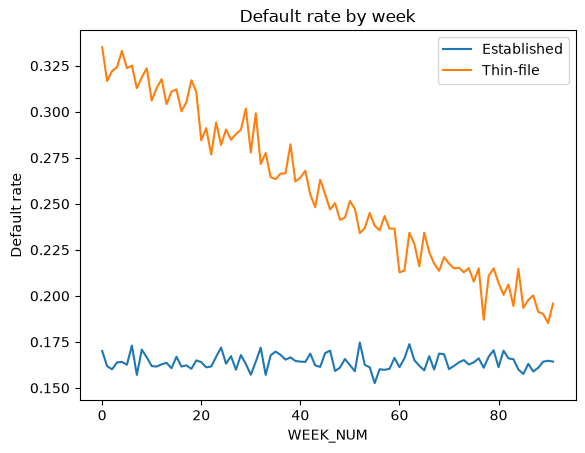

In [4]:
weekly = df.groupby(["WEEK_NUM", "thin_file"])["target"].mean().unstack()
weekly.columns = ["Established", "Thin-file"]
weekly.plot(title="Default rate by week")
plt.ylabel("Default rate")
plt.show()

In [5]:
X_train, y_train = train[features], train["target"]
X_val, y_val = val[features], val["target"]

model = xgb.XGBClassifier(
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=5,
    eval_metric="logloss",
    early_stopping_rounds=50,
    n_jobs=-1,
    random_state=42,
)
model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=100)

val_pd = model.predict_proba(X_val)[:, 1]

[0]	validation_0-logloss:0.45803
[100]	validation_0-logloss:0.39418
[138]	validation_0-logloss:0.39419


In [6]:
y = y_val.values
repaid = (y == 0)
thin = (val["thin_file"] == 1).values

mid_week = val["WEEK_NUM"].median()
early = (val["WEEK_NUM"] <= mid_week).values
late = ~early

In [7]:
print("Number of trees used:", model.best_iteration)

for name, mask in [("Established", val["thin_file"] == 0), ("Thin-file", val["thin_file"] == 1)]:
    y_seg = y_val[mask]
    p_seg = val_pd[mask.values]
    print(name, "| AUC:", round(roc_auc_score(y_seg, p_seg), 3),
          "| actual default:", round(y_seg.mean(), 3),
          "| avg predicted:", round(p_seg.mean(), 3))

Number of trees used: 88
Established | AUC: 0.795 | actual default: 0.164 | avg predicted: 0.165
Thin-file | AUC: 0.711 | actual default: 0.202 | avg predicted: 0.267


In [8]:
weeks = np.sort(train["WEEK_NUM"].unique())
blocks = np.array_split(weeks, 5)

folds = []
for k in range(1, 5):
    fold_train_weeks = np.concatenate(blocks[:k])
    fold_test_weeks = blocks[k]
    folds.append((fold_train_weeks, fold_test_weeks))

for i, (tr_w, te_w) in enumerate(folds, start=1):
    n_tr = train["WEEK_NUM"].isin(tr_w).sum()
    n_te = train["WEEK_NUM"].isin(te_w).sum()
    print("Fold", i, "| train weeks:", tr_w.min(), "-", tr_w.max(), "(", n_tr, "loans )",
          "| test weeks:", te_w.min(), "-", te_w.max(), "(", n_te, "loans )")

Fold 1 | train weeks: 0 - 14 ( 163171 loans ) | test weeks: 15 - 29 ( 162982 loans )
Fold 2 | train weeks: 0 - 29 ( 326153 loans ) | test weeks: 30 - 44 ( 163010 loans )
Fold 3 | train weeks: 0 - 44 ( 489163 loans ) | test weeks: 45 - 59 ( 162970 loans )
Fold 4 | train weeks: 0 - 59 ( 652133 loans ) | test weeks: 60 - 73 ( 152164 loans )


In [9]:
fold_rows = []
for i, (tr_w, te_w) in enumerate(folds, start=1):
    tr = train[train["WEEK_NUM"].isin(tr_w)]
    te = train[train["WEEK_NUM"].isin(te_w)]

    fold_model= xgb.XGBClassifier(
        n_estimators=2000,
        learning_rate=0.05,
        max_depth=5,
        eval_metric="logloss",
        early_stopping_rounds=50,
        n_jobs=-1,
        random_state=42,
    )
    fold_model.fit(tr[features], tr["target"], eval_set=[(te[features], te["target"])], verbose=False)
    p = fold_model.predict_proba(te[features])[:, 1]

    y_te = te["target"].values
    est = (te["thin_file"] == 0).values
    fold_rows.append({"fold": i,
                      "trees": fold_model.best_iteration,
                      "overall_AUC": round(roc_auc_score(y_te, p), 4),
                      "established_AUC": round(roc_auc_score(y_te[est], p[est]), 4),
                      "thin_AUC": round(roc_auc_score(y_te[~est], p[~est]), 4)})

fold_results = pd.DataFrame(fold_rows)
print(fold_results)
print("Average overall AUC:", round(fold_results["overall_AUC"].mean(), 4),
      "| spread (std):", round(fold_results["overall_AUC"].std(), 4))

   fold  trees  overall_AUC  established_AUC  thin_AUC
0     1    104       0.7813           0.7944    0.7115
1     2    122       0.7804           0.7973    0.7186
2     3    119       0.7758           0.7966    0.7158
3     4     96       0.7711           0.7948    0.7141
Average overall AUC: 0.7772 | spread (std): 0.0047


In [10]:
# step 1: how far off is the model on thin-file loans in the early half?
factor = y[thin & early].mean() / val_pd[thin & early].mean()
print("correction factor:", round(factor, 3))

# step 2: multiply the thin-file predictions by that factor
val_pd_fixed = val_pd.copy()
val_pd_fixed[thin] = val_pd[thin] * factor

# step 3: check it on the late half
check = thin & late
print("Thin-file avg predicted before:", round(val_pd[check].mean(), 3),
      "| after:", round(val_pd_fixed[check].mean(), 3),
      "| actual:", round(y[check].mean(), 3))

correction factor: 0.771
Thin-file avg predicted before: 0.268 | after: 0.206 | actual: 0.196


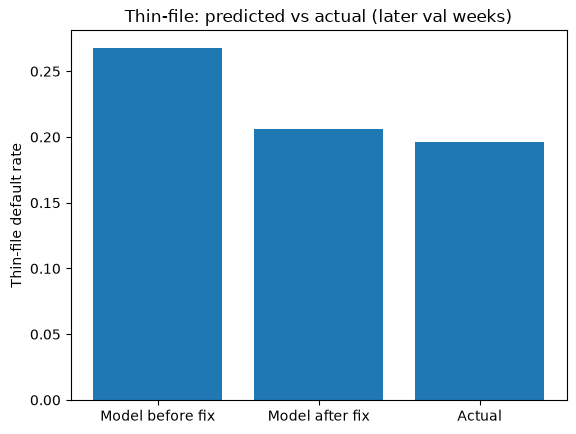

In [11]:
vals = [val_pd[check].mean(), val_pd_fixed[check].mean(), y[check].mean()]
plt.bar(["Model before fix", "Model after fix", "Actual"], vals)
plt.ylabel("Thin-file default rate")
plt.title("Thin-file: predicted vs actual (later val weeks)")
plt.show()

Thin-file Brier | before fix: 0.1498 | after fix: 0.1441


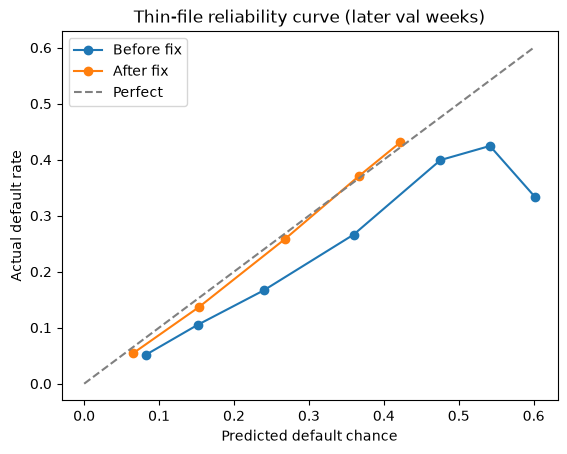

In [12]:
m = late & thin
print("Thin-file Brier | before fix:", round(brier_score_loss(y[m], val_pd[m]), 4),
      "| after fix:", round(brier_score_loss(y[m], val_pd_fixed[m]), 4))

for label, p in [("Before fix", val_pd), ("After fix", val_pd_fixed)]:
    actual, predicted = calibration_curve(y[m], p[m], n_bins=10)
    plt.plot(predicted, actual, marker="o", label=label)
plt.plot([0, 0.6], [0, 0.6], "--", color="gray", label="Perfect")
plt.xlabel("Predicted default chance")
plt.ylabel("Actual default rate")
plt.title("Thin-file reliability curve (later val weeks)")
plt.legend()
plt.show()

In [13]:
print("Overall AUC on val (raw model):", round(roc_auc_score(y_val, val_pd), 4))
print("Later val weeks | raw:", round(roc_auc_score(y[late], val_pd[late]), 4),
      "| after thin-file fix:", round(roc_auc_score(y[late], val_pd_fixed[late]), 4))

Overall AUC on val (raw model): 0.769
Later val weeks | raw: 0.7671 | after thin-file fix: 0.7709


In [14]:
recent = thin & late
final_factor = y[recent].mean() / val_pd[recent].mean()
print("final correction factor:", round(final_factor, 3))

final correction factor: 0.732


In [15]:
val_pd_final = val_pd.copy()
val_pd_final[thin] = val_pd[thin] * final_factor

In [16]:
for name, p in [("Before fix", val_pd), ("After fix", val_pd_fixed)]:
    approve = p < 0.20

    profit = 2000 * (approve & repaid & late).sum() - 8000 * (approve & ~repaid & late).sum()
    established_rate = approve[late & repaid & ~thin].mean()
    thin_rate = approve[late & repaid & thin].mean()

    print(name, "| profit:", int(profit),
          "| established approved:", round(established_rate, 3),
          "| thin-file approved:", round(thin_rate, 3),
          "| gap (points):", round(100 * (established_rate - thin_rate), 1))

Before fix | profit: 63100000 | established approved: 0.781 | thin-file approved: 0.41 | gap (points): 37.1
After fix | profit: 65556000 | established approved: 0.781 | thin-file approved: 0.676 | gap (points): 10.5


In [17]:
for cutoff in [0.20, 0.22, 0.24, 0.26, 0.28]:
    approve = np.where(thin, val_pd_final < cutoff, val_pd_final < 0.20)

    profit = 2000 * (approve & repaid & late).sum() - 8000 * (approve & ~repaid & late).sum()
    established_rate = approve[late & repaid & ~thin].mean()
    thin_rate = approve[late & repaid & thin].mean()

    print("thin-file cutoff:", cutoff, "| profit:", int(profit),
          "| thin-file approved:", round(thin_rate, 3),
          "| gap (points):", round(100 * (established_rate - thin_rate), 1))

thin-file cutoff: 0.2 | profit: 65534000 | thin-file approved: 0.697 | gap (points): 8.3
thin-file cutoff: 0.22 | profit: 65522000 | thin-file approved: 0.699 | gap (points): 8.1
thin-file cutoff: 0.24 | profit: 65538000 | thin-file approved: 0.705 | gap (points): 7.5
thin-file cutoff: 0.26 | profit: 64576000 | thin-file approved: 0.781 | gap (points): -0.0
thin-file cutoff: 0.28 | profit: 62422000 | thin-file approved: 0.878 | gap (points): -9.7


In [18]:
def summarize(approve):
    profit = 2000 * (approve & repaid & late).sum() - 8000 * (approve & ~repaid & late).sum()
    default_rate_approved = (approve & ~repaid & late).sum() / (approve & late).sum()
    est = approve[late & repaid & ~thin].mean()
    th = approve[late & repaid & thin].mean()
    return profit, default_rate_approved, 100 * (est - th)

naive_approve = val_pd < 0.20
final_approve = np.where(thin, val_pd_final < 0.26, val_pd_final < 0.20)

for name, approve in [("Naive (one 20% cutoff)", naive_approve), ("Final policy", final_approve)]:
    profit, rate, gap = summarize(approve)
    print(name, "| profit:", int(profit), "| default rate among approved:", round(rate, 3), "| gap:", round(gap, 1))
    for penalty in [0, 50000, 100000, 200000]:
        print("    penalty per gap point", penalty, "-> score:", int(profit - penalty * max(gap, 0)))

Naive (one 20% cutoff) | profit: 63100000 | default rate among approved: 0.08 | gap: 37.1
    penalty per gap point 0 -> score: 63100000
    penalty per gap point 50000 -> score: 61247229
    penalty per gap point 100000 -> score: 59394458
    penalty per gap point 200000 -> score: 55688917
Final policy | profit: 64576000 | default rate among approved: 0.096 | gap: -0.0
    penalty per gap point 0 -> score: 64576000
    penalty per gap point 50000 -> score: 64576000
    penalty per gap point 100000 -> score: 64576000
    penalty per gap point 200000 -> score: 64576000


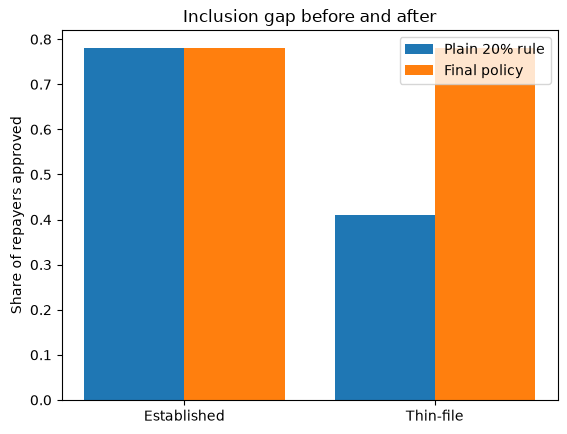

In [19]:
approve_before = val_pd < 0.20
approve_after = np.where(thin, val_pd_final < 0.26, val_pd_final < 0.20)

before = [approve_before[late & repaid & ~thin].mean(), approve_before[late & repaid & thin].mean()]
after = [approve_after[late & repaid & ~thin].mean(), approve_after[late & repaid & thin].mean()]

x = np.arange(2)
plt.bar(x - 0.2, before, width=0.4, label="Plain 20% rule")
plt.bar(x + 0.2, after, width=0.4, label="Final policy")
plt.xticks(x, ["Established", "Thin-file"])
plt.ylabel("Share of repayers approved")
plt.title("Inclusion gap before and after")
plt.legend()
plt.show()

In [20]:
test = pd.read_parquet("../data/test_features.parquet")
X_test = test[features]
test_thin = (test["thin_file"] == 1).values

test_pd = model.predict_proba(X_test)[:, 1]

In [21]:
test_pd_fixed = test_pd.copy()
test_pd_fixed[test_thin] = test_pd[test_thin] * final_factor

test_approve = np.where(test_thin, test_pd_fixed < 0.26, test_pd_fixed < 0.20)
approve_no_fix = test_pd < 0.20

print("Thin-file avg predicted PD | before fix:", round(test_pd[test_thin].mean(), 3),
      "| after fix:", round(test_pd_fixed[test_thin].mean(), 3))
print("Established avg predicted PD:", round(test_pd[~test_thin].mean(), 3))
print("Approval rate, established:", round(test_approve[~test_thin].mean(), 3))
print("Approval rate, thin-file | no fix:", round(approve_no_fix[test_thin].mean(), 3),
      "| with fix and 0.26 cutoff:", round(test_approve[test_thin].mean(), 3))

Thin-file avg predicted PD | before fix: 0.268 | after fix: 0.196
Established avg predicted PD: 0.165
Approval rate, established: 0.71
Approval rate, thin-file | no fix: 0.358 | with fix and 0.26 cutoff: 0.727
